# Panama data and load overview

Inspect the source file's timestamps, sampling frequency and availability assumptions,
then describe load profiles before the development years. Model training and correction
experiments continue in [01_compare_correction_methods.ipynb](01_compare_correction_methods.ipynb).

Select the project's **.venv** kernel and use **Restart Kernel → Run All**.
The only active input is `data/raw/continuous dataset.csv`; settings are read from
`configs/experiment.json`. Source values are preserved. Load values remain in source-data
units because the CSV does not establish their physical unit.


In [1]:
from pathlib import Path
from copy import deepcopy
import sys

sys.dont_write_bytecode = True
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "configs/experiment.json").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from utils.common import read_config
from utils.feature_engineering import feature_columns, load_panama_development, ramp_thresholds
from utils.plotting import ANALYSIS_SIZES, TALTECH_COLORS, analysis_dates, analysis_grid, plot_style
from utils.study import validate_config

%matplotlib inline
pd.options.display.float_format = "{:.4f}".format


C:\Users\danyi\Desktop\TALTECH magister\Magistritöö\xai\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
cfg = read_config()
validate_config(cfg)
DATASETS = tuple(cfg["datasets"])
COUNTRIES = {"panama": "Panama"}


## 1. Source data and availability

The active experiment uses only Panama. Source information was previously checked on
7 November 2026. An earlier timestamp does not establish that a value was publicly
available at a forecast origin.

The source combines measured load, MERRA-2 weather and calendar fields:
[Panama dataset](https://data.mendeley.com/datasets/byx7sztj59/1).
The load source consists of retrospective CND reports. MERRA-2 is released with a
substantially longer delay than the 24-hour shift used here; see the
[MERRA-2 description](https://gmao.gsfc.nasa.gov/reanalysis/MERRA-2/).

Immediate load/error availability, local Panama timestamps and physical units remain
assumptions. This is a historical simulation, not a validated real-time deployment.
The tables distinguish supported source information from assumptions and identify
the exact local CSV using a checksum. They do not verify its units or release history.


In [3]:
from hashlib import sha256

source_assumptions = pd.DataFrame([
    ["Load source", "Supported by source description", "Retrospective CND reports; immediate availability not established"],
    ["Weather release", "Known mismatch", "MERRA-2 release is delayed; a 24-hour shift is not its actual release delay"],
    ["Timestamps", "Assumption", "Timezone-naive CSV interpreted as local Panama time"],
    ["Load units", "Unconfirmed", "CSV has no unit field; results remain in source-data units"],
    ["Load/error availability", "Unconfirmed assumption", "Zero-hour delay in code; publication and revision history absent"],
], columns=["Property", "Status", "Meaning"])
with pd.option_context("display.max_colwidth", None):
    display(source_assumptions)
source_files, source_frequency = [], []
for dataset in DATASETS:
    source_path = ROOT / cfg["datasets"][dataset]["path"]
    stamps = pd.read_csv(source_path, usecols=["datetime"]).datetime
    parsed = pd.to_datetime(stamps, utc=False)
    source_files.append({"Dataset": COUNTRIES[dataset], "File": source_path.name,
                         "Rows": len(parsed), "First timestamp": str(parsed.min()),
                         "Last timestamp": str(parsed.max()), "SHA-256": sha256(source_path.read_bytes()).hexdigest()})
    steps = parsed.diff().dt.total_seconds().div(60)
    for year in sorted(parsed.dt.year.unique()):
        mask = parsed.dt.year.eq(year)
        source_frequency.append({"Dataset": COUNTRIES[dataset], "Year": int(year),
                                 "15-minute steps": int((mask & steps.eq(15)).sum()),
                                 "60-minute steps": int((mask & steps.eq(60)).sum()),
                                 "Other steps": int((mask & steps.notna() & ~steps.isin([15, 60])).sum())})
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(source_files))
display(pd.DataFrame(source_frequency))
print("A checksum identifies the input, not its physical units or release delay.")


,Property,Status,Meaning
0,Load source,Supported by source description,Retrospective CND reports; immediate availability not established
1,Weather release,Known mismatch,MERRA-2 release is delayed; a 24-hour shift is not its actual release delay
2,Timestamps,Assumption,Timezone-naive CSV interpreted as local Panama time
3,Load units,Unconfirmed,CSV has no unit field; results remain in source-data units
4,Load/error availability,Unconfirmed assumption,Zero-hour delay in code; publication and revision history absent


,Dataset,File,Rows,First timestamp,Last timestamp,SHA-256
0,Panama,continuous dataset.csv,48048,2015-01-03 01:00:00,2020-06-27 00:00:00,f41b0204abd18a44e90a456f8951068b6439fecda924cac6b488bbee0acebbc1


,Dataset,Year,15-minute steps,60-minute steps,Other steps
0,Panama,2015,0,8710,0
1,Panama,2016,0,8784,0
2,Panama,2017,0,8760,0
3,Panama,2018,0,8760,0
4,Panama,2019,0,8760,0
5,Panama,2020,0,4273,0


A checksum identifies the input, not its physical units or release delay.


## 2. Development inputs and load profiles

Prepare features from Panama observations before 2020. The charts below describe only
the period before the 2018–2019 development years. Rapid-increase and rapid-decrease
thresholds also use this earlier period. Actual changes determine evaluation groups
only and never enter the forecast inputs. Later development and evaluation observations
are excluded from these descriptive profiles.


In [4]:
panama_options = cfg["datasets"]["panama"]
panama_development, quality = load_panama_development(ROOT / panama_options["path"], cfg)
base_columns, correction_columns = feature_columns("panama")
panama_thresholds = ramp_thresholds(panama_development, panama_options["threshold_end"])

training_view = panama_development[
    panama_development.target_time < panama_options["threshold_end"]
].set_index("target_time")
display(training_view.target_next_hour.describe().to_frame("Pre-development load"))
print("Source rows:", quality["rows"], "| duplicates:", quality["duplicate_timestamps"])

,Pre-development load
count,26087.0000
mean,1157.4774
std,192.3341
min,380.5936
25%,988.0887
50%,1142.5430
75%,1302.7778
max,1645.4773


Source rows: 48048 | duplicates: 0


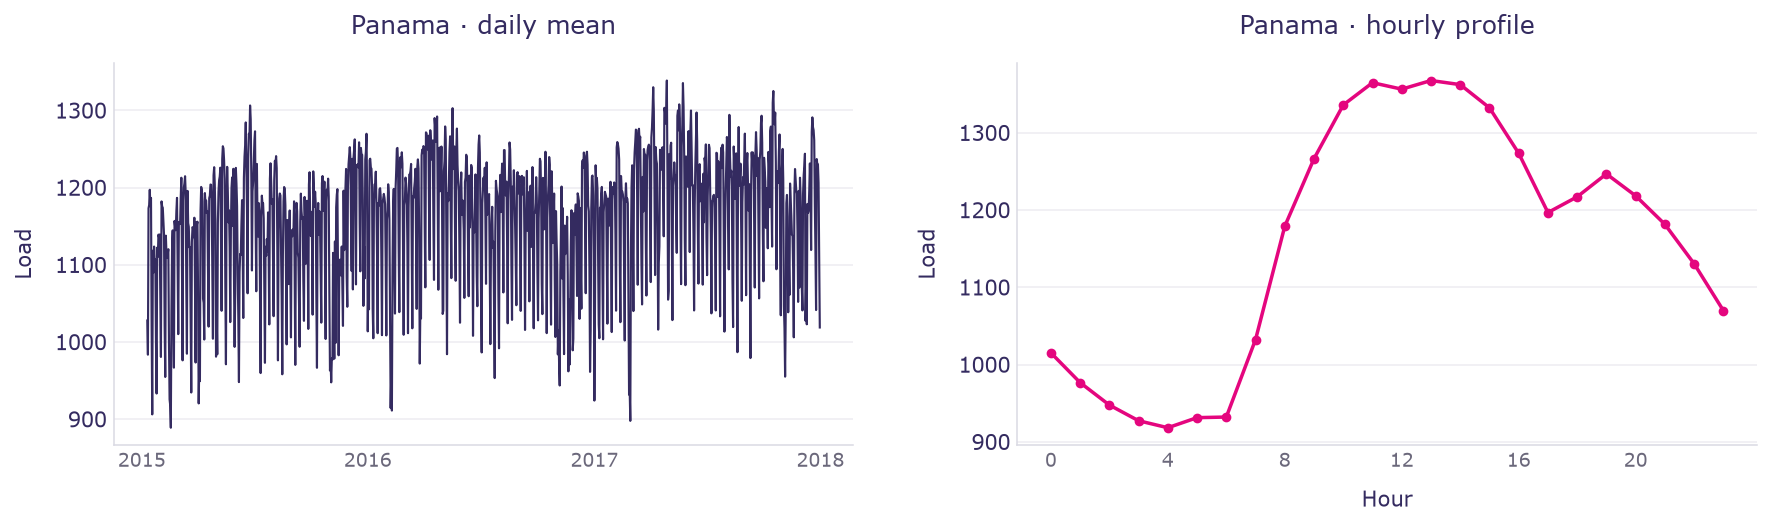

In [5]:
with plot_style("taltech", overrides=ANALYSIS_SIZES):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.1))
    daily = training_view.target_next_hour.resample('D').mean()
    axes[0].plot(daily.index, daily, color=TALTECH_COLORS["ink"], linewidth=1.1)
    axes[0].set(title='Panama · daily mean', ylabel='Load')
    analysis_dates(axes[0])
    hourly = training_view.groupby('hour').target_next_hour.mean()
    axes[1].plot(hourly.index, hourly, color=TALTECH_COLORS["accent"], marker='o', markersize=4)
    axes[1].set(title='Panama · hourly profile', xlabel='Hour', ylabel='Load', xticks=range(0, 24, 4))
    for ax in axes:
        analysis_grid(ax, 'y')
    fig.tight_layout(pad=1.8, w_pad=3)
    plt.show()
